# Customer, Order and Delivery Analysis (Google Colab version)
**Project:** Cart to Door | **Module:** Ashish | **Dataset:** Olist Brazilian E-Commerce

Run cells top to bottom, one at a time (Shift + Enter).

## Step 1 – Install PySpark + Delta Lake (run once, ~1-2 min)

In [18]:
!pip -q install pyspark==3.5.1 delta-spark==3.2.0

## Step 2 – Start Spark with Delta support

In [19]:
from pyspark.sql import SparkSession, functions as F
from delta import configure_spark_with_delta_pip

builder = (SparkSession.builder.appName("Ashish_Olist_Analysis")
    .master("local[*]")
    .config("spark.sql.extensions", "io.delta.sql.DeltaSparkSessionExtension")
    .config("spark.sql.catalog.spark_catalog", "org.apache.spark.sql.delta.catalog.DeltaCatalog")
    .config("spark.driver.memory", "4g"))
spark = configure_spark_with_delta_pip(builder).getOrCreate()

print("Welcome to Ashish's E-Commerce Analysis")
print("Spark Version:", spark.version)
print("Spark is ready!")

# helper: pretty tables in Colab (replaces Databricks display())
from IPython.display import display as _d
def show(df, n=50):
    _d(df.limit(n).toPandas())

Welcome to Ashish's E-Commerce Analysis
Spark Version: 3.5.1
Spark is ready!


In [20]:
!ls -la /content

total 39612
drwxr-xr-x 1 root root     4096 Nov 18 05:06  .
drwxr-xr-x 1 root root     4096 Nov 18 04:48  ..
drwxr-xr-x 4 root root     4096 Oct 26 22:18  .config
-rw-r--r-- 1 root root  9033957 Nov 18 05:04 'olist_customers_dataset (1).csv'
-rw-r--r-- 1 root root  9033957 Nov 18 05:06  olist_customers_dataset.csv
-rw-r--r-- 1 root root  4814694 Nov 18 04:59  olist_customers_dataset.csv.zip
-rw-r--r-- 1 root root 17654914 Nov 18 05:06  olist_orders_dataset.csv
drwxr-xr-x 1 root root     4096 Oct 26 22:18  sample_data


In [21]:
!pip -q install kagglehub
import kagglehub, shutil, glob

path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")
print("Downloaded to:", path)

for name in ["olist_orders_dataset.csv", "olist_customers_dataset.csv"]:
    shutil.copy(f"{path}/{name}", f"/content/{name}")

!ls -la /content/*.csv

Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
Downloaded to: /kaggle/input/brazilian-ecommerce
-rw-r--r-- 1 root root  9033957 Nov 18 05:04 '/content/olist_customers_dataset (1).csv'
-rw-r--r-- 1 root root  9033957 Nov 18 05:08  /content/olist_customers_dataset.csv
-rw-r--r-- 1 root root 17654914 Nov 18 05:08  /content/olist_orders_dataset.csv


## Step 4 – Load orders and customers

In [22]:
orders = (spark.read.option("header", True).option("inferSchema", True)
          .csv("/content/olist_orders_dataset.csv"))
customers = (spark.read.option("header", True).option("inferSchema", True)
             .csv("/content/olist_customers_dataset.csv"))

print("Orders loaded! Rows:", orders.count(), "| Columns:", len(orders.columns))
orders.show(5, truncate=False)
print("Customers loaded! Rows:", customers.count(), "| Columns:", len(customers.columns))
customers.show(5, truncate=False)
orders.printSchema()

Orders loaded! Rows: 99441 | Columns: 8
+--------------------------------+--------------------------------+------------+------------------------+-------------------+----------------------------+-----------------------------+-----------------------------+
|order_id                        |customer_id                     |order_status|order_purchase_timestamp|order_approved_at  |order_delivered_carrier_date|order_delivered_customer_date|order_estimated_delivery_date|
+--------------------------------+--------------------------------+------------+------------------------+-------------------+----------------------------+-----------------------------+-----------------------------+
|e481f51cbdc54678b7cc49136f2d6af7|9ef432eb6251297304e76186b10a928d|delivered   |2017-10-02 10:56:33     |2017-10-02 11:07:15|2017-10-04 19:55:00         |2017-10-10 21:25:13          |2017-10-18 00:00:00          |
|53cdb2fc8bc7dce0b6741e2150273451|b0830fb4747a6c6d20dea0b8c802d7ef|delivered   |2018-07-24 20:41:37 

## Step 5 – Missing values and data-quality checks

In [23]:
def null_counts(df):
    return df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns])

print("Missing values – orders")
show(null_counts(orders))
print("Missing values – customers")
show(null_counts(customers))

print("Duplicate order_id rows    :", orders.count() - orders.select("order_id").distinct().count())
print("Duplicate customer_id rows :", customers.count() - customers.select("customer_id").distinct().count())
print("Unique real customers      :", customers.select("customer_unique_id").distinct().count())

Missing values – orders


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,0,0,0,0,160,1783,2965,0


Missing values – customers


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,0,0,0,0,0


Duplicate order_id rows    : 0
Duplicate customer_id rows : 0
Unique real customers      : 96096


## Step 6 – Order status analysis

In [24]:
status_analysis = (orders.groupBy("order_status")
    .agg(F.count("order_id").alias("total_orders"))
    .orderBy(F.col("total_orders").desc()))
show(status_analysis)

,order_status,total_orders
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


## Step 7 – Monthly orders

In [25]:
orders_with_month = orders.withColumn(
    "order_month", F.date_format(F.to_timestamp("order_purchase_timestamp"), "yyyy-MM"))
monthly_orders = (orders_with_month.groupBy("order_month")
    .agg(F.count("order_id").alias("total_orders"))
    .orderBy("order_month"))
show(monthly_orders)
print("NULL months (should be 0):", orders_with_month.filter(F.col("order_month").isNull()).count())

,order_month,total_orders
0,2016-09,4
1,2016-10,324
2,2016-12,1
3,2017-01,800
4,2017-02,1780
5,2017-03,2682
6,2017-04,2404
7,2017-05,3700
8,2017-06,3245
9,2017-07,4026


NULL months (should be 0): 0


## Step 8 – Actual vs estimated delivery
Positive = late, negative = early, 0 = on expected date.

In [26]:
delivery_data = (orders
    .withColumn("actual_delivery_date",   F.to_timestamp("order_delivered_customer_date"))
    .withColumn("expected_delivery_date", F.to_timestamp("order_estimated_delivery_date"))
    .withColumn("delivery_difference_days",
                F.datediff(F.col("actual_delivery_date"), F.col("expected_delivery_date"))))
delivery_data.select("order_id","actual_delivery_date","expected_delivery_date",
                     "delivery_difference_days").show(10, truncate=False)

+--------------------------------+--------------------+----------------------+------------------------+
|order_id                        |actual_delivery_date|expected_delivery_date|delivery_difference_days|
+--------------------------------+--------------------+----------------------+------------------------+
|e481f51cbdc54678b7cc49136f2d6af7|2017-10-10 21:25:13 |2017-10-18 00:00:00   |-8                      |
|53cdb2fc8bc7dce0b6741e2150273451|2018-08-07 15:27:45 |2018-08-13 00:00:00   |-6                      |
|47770eb9100c2d0c44946d9cf07ec65d|2018-08-17 18:06:29 |2018-09-04 00:00:00   |-18                     |
|949d5b44dbf5de918fe9c16f97b45f8a|2017-12-02 00:28:42 |2017-12-15 00:00:00   |-13                     |
|ad21c59c0840e6cb83a9ceb5573f8159|2018-02-16 18:17:02 |2018-02-26 00:00:00   |-10                     |
|a4591c265e18cb1dcee52889e2d8acc3|2017-07-26 10:57:55 |2017-08-01 00:00:00   |-6                      |
|136cce7faa42fdb2cefd53fdc79a6098|NULL                |2017-05-0

## Step 9 – Early / On-time / Late (delivered orders only)

In [27]:
delivered_orders = delivery_data.filter(F.col("actual_delivery_date").isNotNull())
delivery_summary = delivered_orders.withColumn(
    "delivery_category",
    F.when(F.col("delivery_difference_days") > 0, "Late Delivery")
     .when(F.col("delivery_difference_days") < 0, "Early Delivery")
     .otherwise("On-Time Delivery"))
delivery_counts = delivery_summary.groupBy("delivery_category").count().orderBy(F.col("count").desc())
show(delivery_counts)
print("Delivered orders analysed:", delivered_orders.count())

,delivery_category,count
0,Early Delivery,88649
1,Late Delivery,6535
2,On-Time Delivery,1292


Delivered orders analysed: 96476


## Step 10 – Average delivery time

In [28]:
delivery_time = delivered_orders.withColumn(
    "delivery_days",
    F.datediff(F.col("actual_delivery_date"), F.to_timestamp("order_purchase_timestamp")))
delivery_time.select(F.round(F.avg("delivery_days"), 2).alias("average_delivery_days")).show()

+---------------------+
|average_delivery_days|
+---------------------+
|                 12.5|
+---------------------+



## Step 11 – Top customer cities (customer records)

In [29]:
customer_city_analysis = (customers.groupBy("customer_city")
    .agg(F.count("customer_id").alias("total_customers"))
    .orderBy(F.col("total_customers").desc()))
show(customer_city_analysis, 10)

,customer_city,total_customers
0,sao paulo,15540
1,rio de janeiro,6882
2,belo horizonte,2773
3,brasilia,2131
4,curitiba,1521
5,campinas,1444
6,porto alegre,1379
7,salvador,1245
8,guarulhos,1189
9,sao bernardo do campo,938


## Step 12 – JOIN orders + customers, city-wise orders

In [30]:
customer_orders = orders.join(customers, on="customer_id", how="inner")
print("Joined successfully! Orders:", orders.count(), "| Joined rows:", customer_orders.count(), "(should be equal)")

city_orders = (customer_orders.groupBy("customer_city")
    .agg(F.count("order_id").alias("total_orders"))
    .orderBy(F.col("total_orders").desc()))
show(city_orders, 10)

Joined successfully! Orders: 99441 | Joined rows: 99441 (should be equal)


,customer_city,total_orders
0,sao paulo,15540
1,rio de janeiro,6882
2,belo horizonte,2773
3,brasilia,2131
4,curitiba,1521
5,campinas,1444
6,porto alegre,1379
7,salvador,1245
8,guarulhos,1189
9,sao bernardo do campo,938


## Step 13 – Final delivery + customer table

In [31]:
final_analysis = delivery_summary.join(customers, on="customer_id", how="left")
assert final_analysis.count() == delivery_summary.count(), "Join created duplicate rows!"

final_analysis = final_analysis.select(
    "order_id","customer_id","customer_unique_id","customer_city","customer_state",
    "order_status","order_purchase_timestamp","actual_delivery_date","expected_delivery_date",
    "delivery_difference_days","delivery_category")
final_analysis.show(20, truncate=False)

+--------------------------------+--------------------------------+--------------------------------+-----------------------+--------------+------------+------------------------+--------------------+----------------------+------------------------+-----------------+
|order_id                        |customer_id                     |customer_unique_id              |customer_city          |customer_state|order_status|order_purchase_timestamp|actual_delivery_date|expected_delivery_date|delivery_difference_days|delivery_category|
+--------------------------------+--------------------------------+--------------------------------+-----------------------+--------------+------------+------------------------+--------------------+----------------------+------------------------+-----------------+
|e481f51cbdc54678b7cc49136f2d6af7|9ef432eb6251297304e76186b10a928d|7c396fd4830fd04220f754e42b4e5bff|sao paulo              |SP            |delivered   |2017-10-02 10:56:33     |2017-10-10 21:25:13 |2017-10

## Step 14 – Save as Delta table (Gold)

In [32]:
GOLD_PATH = "/content/ashish_customer_delivery_gold"
(final_analysis.write.format("delta").mode("overwrite")
    .option("overwriteSchema", "true").save(GOLD_PATH))
print("Final Delta Table Created Successfully!")

saved = spark.read.format("delta").load(GOLD_PATH)
print("Saved Records:", saved.count())
saved.show(10, truncate=False)

Final Delta Table Created Successfully!
Saved Records: 96476
+--------------------------------+--------------------------------+--------------------------------+-----------------------+--------------+------------+------------------------+--------------------+----------------------+------------------------+-----------------+
|order_id                        |customer_id                     |customer_unique_id              |customer_city          |customer_state|order_status|order_purchase_timestamp|actual_delivery_date|expected_delivery_date|delivery_difference_days|delivery_category|
+--------------------------------+--------------------------------+--------------------------------+-----------------------+--------------+------------+------------------------+--------------------+----------------------+------------------------+-----------------+
|e481f51cbdc54678b7cc49136f2d6af7|9ef432eb6251297304e76186b10a928d|7c396fd4830fd04220f754e42b4e5bff|sao paulo              |SP            |deliv

## Step 15 – Charts (screenshot these)

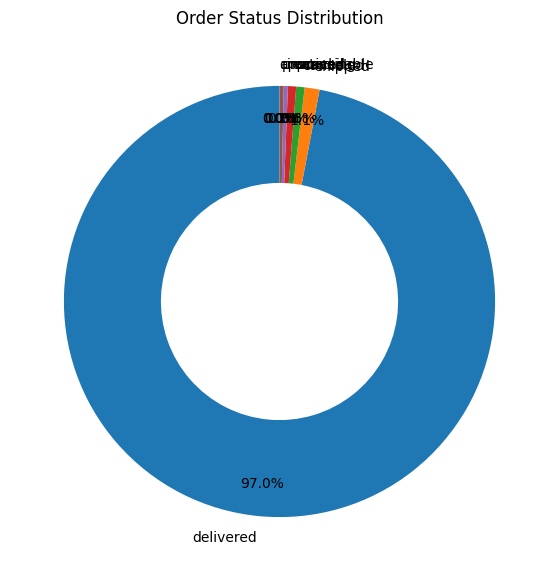

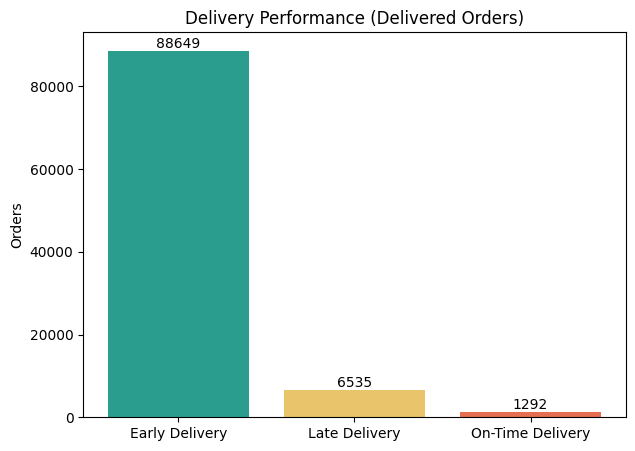

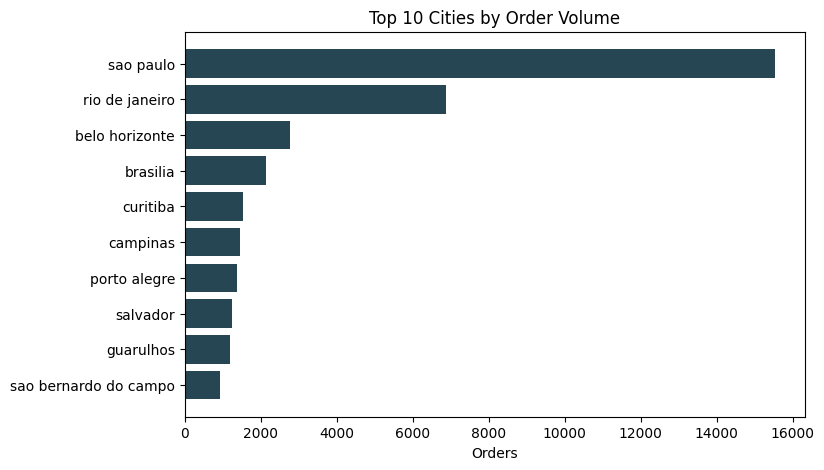

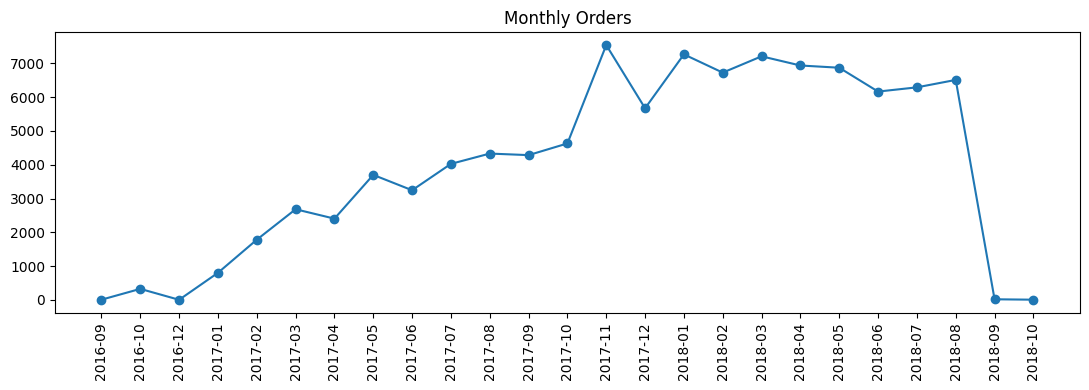

In [33]:
import matplotlib.pyplot as plt

s = status_analysis.toPandas()
plt.figure(figsize=(7,7))
plt.pie(s["total_orders"], labels=s["order_status"], autopct="%1.1f%%", startangle=90,
        pctdistance=0.85, wedgeprops=dict(width=0.45))
plt.title("Order Status Distribution"); plt.show()

d = delivery_counts.toPandas()
plt.figure(figsize=(7,5))
bars = plt.bar(d["delivery_category"], d["count"], color=["#2a9d8f","#e9c46a","#e76f51"][:len(d)])
plt.bar_label(bars); plt.title("Delivery Performance (Delivered Orders)"); plt.ylabel("Orders"); plt.show()

c = city_orders.limit(10).toPandas().iloc[::-1]
plt.figure(figsize=(8,5))
plt.barh(c["customer_city"], c["total_orders"], color="#264653")
plt.title("Top 10 Cities by Order Volume"); plt.xlabel("Orders"); plt.show()

m = monthly_orders.toPandas()
plt.figure(figsize=(11,4))
plt.plot(m["order_month"], m["total_orders"], marker="o")
plt.xticks(rotation=90); plt.title("Monthly Orders"); plt.tight_layout(); plt.show()

## Step 16 – Business findings (auto-filled from real results)

In [34]:
st  = status_analysis.collect()
mo  = monthly_orders.collect()
dc  = {r["delivery_category"]: r["count"] for r in delivery_counts.collect()}
avg = delivery_time.select(F.avg("delivery_days")).first()[0]
top_cities = city_orders.limit(10).collect()
mo_sorted = sorted(mo, key=lambda r: r["total_orders"])

findings = f"""
# CUSTOMER, ORDER AND DELIVERY FINDINGS

## 1. Order Analysis
- Total orders analysed: {orders.count():,}
- Most common order status: {st[0]["order_status"]} ({st[0]["total_orders"]:,})
- Least common order status: {st[-1]["order_status"]} ({st[-1]["total_orders"]:,})

## 2. Monthly Analysis
- Highest order month: {mo_sorted[-1]["order_month"]} ({mo_sorted[-1]["total_orders"]:,} orders)
- Lowest order month: {mo_sorted[0]["order_month"]} ({mo_sorted[0]["total_orders"]:,} orders)
  (Note: first and last months of the dataset are partial, so the lowest month may reflect incomplete data.)

## 3. Delivery Analysis
- Average delivery time: {avg:.2f} days
- Total early deliveries: {dc.get("Early Delivery",0):,}
- Total on-time deliveries: {dc.get("On-Time Delivery",0):,}
- Total late deliveries: {dc.get("Late Delivery",0):,}

## 4. Customer Analysis
- Top customer city: {top_cities[0]["customer_city"]} ({top_cities[0]["total_orders"]:,} orders)
- Total customer records: {customers.count():,}
- Top 10 cities by order volume: {", ".join(f"{r['customer_city']} ({r['total_orders']:,})" for r in top_cities)}

## 5. Business Recommendations
- Improve delivery tracking.
- Investigate reasons for late deliveries.
- Monitor cities with high order volume.
- Improve customer communication.
"""
print(findings)
with open("/content/Business_Findings.md", "w") as f:
    f.write(findings)


# CUSTOMER, ORDER AND DELIVERY FINDINGS

## 1. Order Analysis
- Total orders analysed: 99,441
- Most common order status: delivered (96,478)
- Least common order status: approved (2)

## 2. Monthly Analysis
- Highest order month: 2017-11 (7,544 orders)
- Lowest order month: 2016-12 (1 orders)
  (Note: first and last months of the dataset are partial, so the lowest month may reflect incomplete data.)

## 3. Delivery Analysis
- Average delivery time: 12.50 days
- Total early deliveries: 88,649
- Total on-time deliveries: 1,292
- Total late deliveries: 6,535

## 4. Customer Analysis
- Top customer city: sao paulo (15,540 orders)
- Total customer records: 99,441
- Top 10 cities by order volume: sao paulo (15,540), rio de janeiro (6,882), belo horizonte (2,773), brasilia (2,131), curitiba (1,521), campinas (1,444), porto alegre (1,379), salvador (1,245), guarulhos (1,189), sao bernardo do campo (938)

## 5. Business Recommendations
- Improve delivery tracking.
- Investigate reasons for lat

## Step 17 – Download your outputs (for the submission folder)

In [35]:
import shutil
from google.colab import files

# Gold table as one CSV + zipped Delta folder + findings
final_analysis.toPandas().to_csv("/content/ashish_customer_delivery_gold.csv", index=False)
shutil.make_archive("/content/ashish_customer_delivery_gold_delta", "zip", GOLD_PATH)

files.download("/content/Business_Findings.md")
files.download("/content/ashish_customer_delivery_gold.csv")
files.download("/content/ashish_customer_delivery_gold_delta.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>